Data Preprocessing and Exploratory Data Analysis
1. Introduction

The objective of this project is to select a suitable dataset, perform exploratory data analysis, handle missing values, encode categorical variables, and prepare features for machine learning.

2. Dataset Description

The Palmer Penguins dataset contains information about three penguin species: Adelie, Chinstrap, and Gentoo. It includes measurements such as bill length, bill depth, flipper length, and body mass, along with categorical information such as island and sex.

3. Project Objectives
Explore the dataset using statistical summaries and visualizations.
Identify and handle missing values.
Encode categorical variables into numerical values.
Prepare input features and the target variable.
Split the data into training and testing sets.
4. Libraries Used

Python, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.

In [ ]:

# Step 3: Import libraries and load the dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Palmer Penguins dataset
df = sns.load_dataset("penguins")

# Display the first five rows
print("First five rows of the dataset:")
display(df.head())

# Display the number of rows and columns
print("Dataset shape:", df.shape)


First five rows of the dataset:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


Dataset shape: (344, 7)


5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the structure, characteristics, and quality of the dataset before preprocessing. In this step, we will examine the dataset dimensions, column data types, summary statistics, missing values, and duplicate records.

In [ ]:

# Display the dataset dimensions
print("Number of rows and columns:", df.shape)

# Display column names and data types
print("\nDataset information:")
df.info()

# Display summary statistics
print("\nSummary statistics:")
display(df.describe(include="all"))

# Count missing values in each column
print("\nMissing values in each column:")
display(df.isnull().sum())

# Count duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())


Number of rows and columns: (344, 7)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB

Summary statistics:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
count,344,344,342.000000,342.000000,342.000000,342.000000,333
unique,3,3,NaN,NaN,NaN,NaN,2
top,Adelie,Biscoe,NaN,NaN,NaN,NaN,Male
freq,152,168,NaN,NaN,NaN,NaN,168
mean,NaN,NaN,43.921930,17.151170,200.915205,4201.754386,NaN
std,NaN,NaN,5.459584,1.974793,14.061714,801.954536,NaN
min,NaN,NaN,32.100000,13.100000,172.000000,2700.000000,NaN
25%,NaN,NaN,39.225000,15.600000,190.000000,3550.000000,NaN
50%,NaN,NaN,44.450000,17.300000,197.000000,4050.000000,NaN
75%,NaN,NaN,48.500000,18.700000,213.000000,4750.000000,NaN



Missing values in each column:


,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11



Number of duplicate rows: 0


6. Data Visualization

Data visualization helps us understand patterns, distributions, and relationships within the dataset. In this section, we will visualize penguin species distribution, body mass, and the relationship between bill measurements.

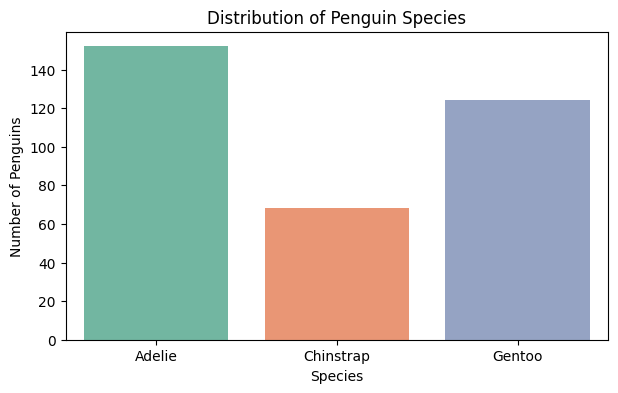

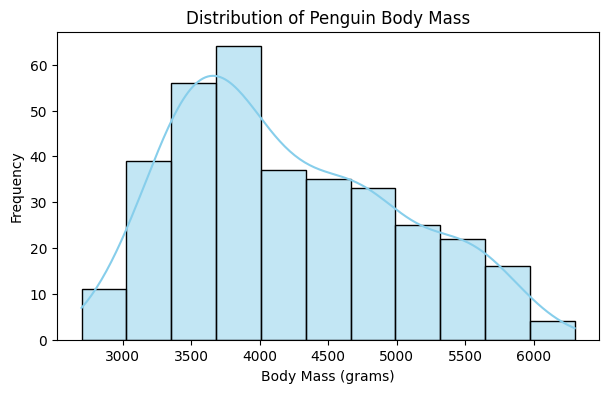

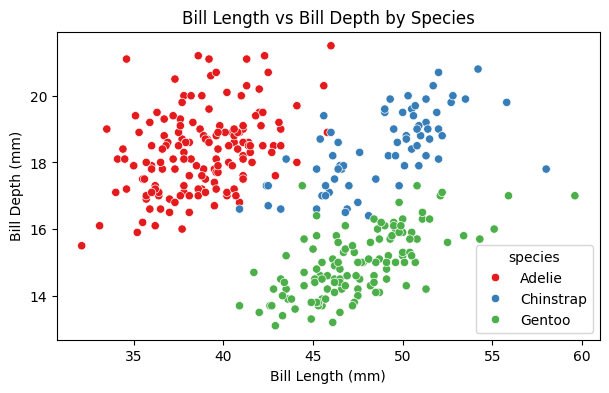

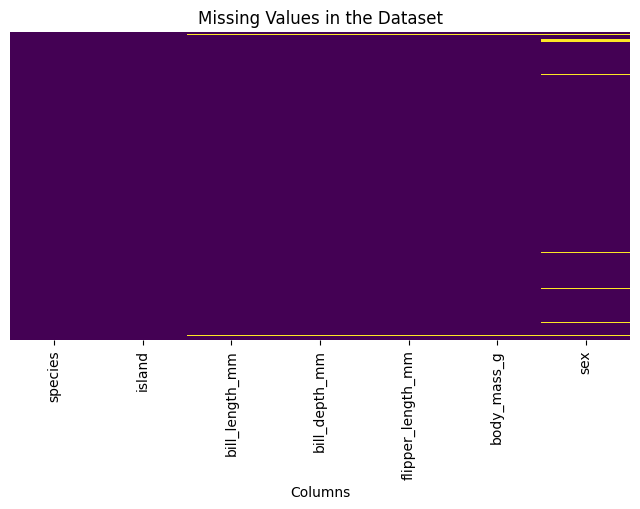

In [ ]:

# Chart 1: Count of each penguin species
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="species", hue="species", palette="Set2", legend=False)
plt.title("Distribution of Penguin Species")
plt.xlabel("Species")
plt.ylabel("Number of Penguins")
plt.show()

# Chart 2: Distribution of body mass
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="body_mass_g", kde=True, color="skyblue")
plt.title("Distribution of Penguin Body Mass")
plt.xlabel("Body Mass (grams)")
plt.ylabel("Frequency")
plt.show()

# Chart 3: Bill length vs bill depth
plt.figure(figsize=(7, 4))
sns.scatterplot(
    data=df,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="species",
    palette="Set1"
)
plt.title("Bill Length vs Bill Depth by Species")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.show()

# Chart 4: Missing values heatmap
plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Values in the Dataset")
plt.xlabel("Columns")
plt.show()


7. Handling Missing Values

Missing values can affect the quality of data analysis and machine learning. In this step, we will identify missing values and handle them using suitable imputation techniques.

Numerical columns: Missing values will be replaced with the median.
Categorical columns: Missing values will be replaced with the most frequent value (mode).

The median is less affected by extreme values, while the mode is suitable for categorical data.

In [ ]:

# Check missing values before treatment
print("Missing values before treatment:")
display(df.isnull().sum())

# Create a copy of the dataset
df_clean = df.copy()

# Handle missing numerical values using the median
numerical_cols = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

for col in numerical_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Handle missing categorical values using the mode
categorical_cols = ["species", "island", "sex"]

for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# Check missing values after treatment
print("\nMissing values after treatment:")
display(df_clean.isnull().sum())

print("\nCleaned dataset shape:", df_clean.shape)


Missing values before treatment:


,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11



Missing values after treatment:


,0
species,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0



Cleaned dataset shape: (344, 7)


8. Encoding Categorical Variables

Categorical variables contain text labels rather than numerical values. To prepare the dataset for machine learning, we will use one-hot encoding to convert categorical input features into numerical columns.

The target variable, species, will remain separate because it represents the class we want to predict.

In [ ]:

# Separate input features and target variable
X = df_clean.drop(columns=["species"])
y = df_clean["species"]

# Apply one-hot encoding to categorical input features
X_encoded = pd.get_dummies(
    X,
    columns=["island", "sex"],
    drop_first=False,
    dtype=int
)

# Display the encoded dataset
print("Encoded feature dataset:")
display(X_encoded.head())

print("\nEncoded feature shape:", X_encoded.shape)
print("\nTarget variable:")
display(y.head())

print("\nEncoded column names:")
print(X_encoded.columns.tolist())


Encoded feature dataset:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Biscoe,island_Dream,island_Torgersen,sex_Female,sex_Male
0,39.10,18.7,181.0,3750.0,0,0,1,0,1
1,39.50,17.4,186.0,3800.0,0,0,1,1,0
2,40.30,18.0,195.0,3250.0,0,0,1,1,0
3,44.45,17.3,197.0,4050.0,0,0,1,0,1
4,36.70,19.3,193.0,3450.0,0,0,1,1,0



Encoded feature shape: (344, 9)

Target variable:


,species
0,Adelie
1,Adelie
2,Adelie
3,Adelie
4,Adelie



Encoded column names:
['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'island_Biscoe', 'island_Dream', 'island_Torgersen', 'sex_Female', 'sex_Male']


9. Feature Preparation and Train-Test Split

In this step, the dataset is divided into training and testing sets. The training set is used to prepare a machine-learning model, while the testing set can later be used to evaluate its performance.

We will use 80% of the data for training and 20% for testing. Numerical features will be standardized, and categorical features will be encoded for machine-learning compatibility.

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split features and target into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize the numerical measurement columns
scaler = StandardScaler()

X_train[numerical_cols] = scaler.fit_transform(
    X_train[numerical_cols]
)

X_test[numerical_cols] = scaler.transform(
    X_test[numerical_cols]
)

# Display dataset dimensions
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nFeature preparation completed successfully!")


Training features shape: (275, 9)
Testing features shape: (69, 9)
Training target shape: (275,)
Testing target shape: (69,)

Feature preparation completed successfully!


10. Conclusion

In this project, the Palmer Penguins dataset was selected for exploratory data analysis and data preprocessing.

The dataset was explored using summary statistics and visualizations. Missing numerical values were handled using median imputation, and missing categorical values were handled using mode imputation.

Categorical input features were converted into numerical columns using one-hot encoding. The numerical features were standardized, and the dataset was divided into training and testing sets.

The resulting data is prepared for use in a future machine-learning classification model.